# Chuẩn bị dữ liệu (Chương 3)


In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)

# ----- THAM SỐ -----
DATA_DIR      = os.environ.get('DATA_DIR', '../Datasets')
OUT_DIR       = os.environ.get('OUT_DIR', '../Datasets')
TZ            = 'America/Los_Angeles'
WINDOW_START  = pd.Timestamp('2018-06-12')
END_DATE      = pd.Timestamp('2018-10-03')
K             = 14            # ngưỡng churn: im lặng >= K ngày
LANDMARK      = 14            # mốc landmark (ngày kể từ cài đặt)
COHORT        = 'verified'    # 'verified' | 'first_open' | 'first_touch'
MAX_GAP_DAYS  = 1             # độ trễ tối đa first touch -> sự kiện đầu (cohort 'verified')
CENSOR_AT     = 'standard'    # 'standard' (censor tại END-K, loại cài muộn) | 'last_active' | 'end'
SYSTEM_EVENTS = {'firebase_campaign', 'os_update', 'app_update', 'app_remove', 'app_clear_data'}

assert COHORT in ('verified', 'first_open', 'first_touch') and CENSOR_AT in ('standard', 'last_active', 'end')
print('Số ngày quan sát tối đa:', (END_DATE - WINDOW_START).days + 1)


Số ngày quan sát tối đa: 114


## 1. Đọc dữ liệu và kiểm tra tính toàn vẹn

In [2]:
def d8(s):  # 20180612 -> Timestamp
    return pd.to_datetime(s.astype(str), format='%Y%m%d')

def find(*names):
    for n in names:
        p = os.path.join(DATA_DIR, n)
        if os.path.exists(p): return p
    raise FileNotFoundError(names)

dim = pd.read_csv(find('dim_user.csv'))
evd = pd.read_csv(find('fact_event_daily.csv'), parse_dates=['event_date'])
lvl_raw = pd.read_csv(find('fact_level.csv'))
# Chọn đúng file fact_screen THÔ (có cột screen_class); bỏ qua bản cũ đã gộp theo ngày
scr = None
for n in ['fact_screen_1.csv', 'fact_screen.csv']:
    p = os.path.join(DATA_DIR, n)
    if os.path.exists(p):
        cand = pd.read_csv(p)
        if 'screen_class' in cand.columns:
            scr = cand; print('fact_screen đọc từ', n, '| số dòng:', len(cand)); break
assert scr is not None, 'Không tìm thấy fact_screen thô (cần cột screen_class)'
eco = pd.read_csv(find('fact_economy.csv'))

# --- kiểm tra toàn vẹn giữa các bảng ---
assert dim.user_pseudo_id.is_unique and len(dim) == 2284, 'dim_user phải 2.284 user duy nhất'
assert evd.user_pseudo_id.nunique() == len(dim)
assert not evd.duplicated(['user_pseudo_id', 'event_date', 'event_name']).any()
tot = evd.groupby('event_name').n_events.sum()
assert len(lvl_raw) == tot[tot.index.str.startswith('level_')].sum(), 'fact_level lệch fact_event_daily'
assert len(scr) == tot['screen_view'], 'fact_screen lệch fact_event_daily'
for ev in eco.event_name.unique():
    assert (eco.event_name == ev).sum() == tot[ev], f'fact_economy lệch ở {ev}'
for name, df in [('level', lvl_raw), ('screen', scr), ('economy', eco)]:
    assert set(df.user_pseudo_id) <= set(dim.user_pseudo_id), f'{name}: user lạ'

prof = pd.read_csv(os.path.join(DATA_DIR, 'event_param_profile.csv'))
ss = prof[prof.event_name == 'session_start'].sort_values('pct_events', ascending=False)
display(ss)
has_sid = prof.param_key.isin(['ga_session_id', 'ga_session_number']).sum()
print('Số khóa mã phiên trong toàn bộ mẫu:', has_sid)
assert has_sid == 0, 'Dữ liệu CÓ mã phiên: phải sửa lập luận ở Chương 3'

# --- làm sạch ---
lvl = lvl_raw.drop_duplicates().copy()
print(f'fact_level: bỏ {len(lvl_raw) - len(lvl)} dòng trùng hoàn toàn')
scr = scr.drop_duplicates().copy()
lvl['event_date'] = d8(lvl.event_date); scr['event_date'] = d8(scr.event_date); eco['event_date'] = d8(eco.event_date)
lvl['level_number'] = (lvl.level_int.fillna(lvl.level_double.round())
                         .fillna(lvl.level_name.str.extract(r'(\d+)$')[0].astype(float)))
assert (lvl.loc[lvl.event_name.str.endswith('_quickplay'), 'level_number'].isna()).all()
print('Sự kiện level thường thiếu level_number:', int((~lvl.event_name.str.endswith('_quickplay') & lvl.level_number.isna()).sum()))
print('Khoảng ngày fact_event_daily:', evd.event_date.min().date(), '->', evd.event_date.max().date())
assert evd.event_date.min() == WINDOW_START and evd.event_date.max() == END_DATE


fact_screen đọc từ fact_screen.csv | số dòng: 364751


,event_name,param_key,value_type,n_params,n_users,n_events,pct_events
193,session_start,firebase_event_origin,string,11565,1841,11565,1.000000
194,session_start,firebase_conversion,int,11528,1830,11565,0.996801
195,session_start,firebase_screen_class,string,11497,1833,11565,0.994120
196,session_start,firebase_screen_id,int,11497,1833,11565,0.994120
197,session_start,firebase_screen,string,128,42,11565,0.011068


Số khóa mã phiên trong toàn bộ mẫu: 0
fact_level: bỏ 6 dòng trùng hoàn toàn
Sự kiện level thường thiếu level_number: 151
Khoảng ngày fact_event_daily: 2018-06-12 -> 2018-10-03


## 2. Dựng bảng user, Event, T, Entry (Nhóm A)

In [3]:
base = dim[['user_pseudo_id', 'first_touch_ts', 'first_open_date', 'country', 'platform',
            'device_category', 'ltv_revenue']].copy()
base['first_touch_date'] = (pd.to_datetime(base.first_touch_ts, utc=True)
                              .dt.tz_convert(TZ).dt.tz_localize(None).dt.normalize())
base['first_open_date'] = pd.to_datetime(base.first_open_date)
base['has_first_open'] = base.first_open_date.notna()
base['ltv_revenue'] = base.ltv_revenue.fillna(0.0)
base['has_spent'] = (base.ltv_revenue > 0).astype(int)
base = base.drop(columns='first_touch_ts')

# Kiểm tra múi giờ: first touch (UTC) đổi về múi giờ nào thì KHÔNG muộn hơn ngày sự kiện đầu?
_ft = pd.to_datetime(dim.first_touch_ts, utc=True); _fe = pd.to_datetime(dim.first_event_date)
tz_check = {tz: int((_ft.dt.tz_convert(tz).dt.tz_localize(None).dt.normalize() > _fe).sum())
            for tz in ['UTC', TZ, 'America/New_York', 'Asia/Ho_Chi_Minh']}
print('Số user có ngày first touch muộn hơn ngày sự kiện đầu, theo múi giờ:', tz_check)
assert tz_check[TZ] == 0, 'Múi giờ TZ không khớp event_date'
print(f'Doanh thu: {int(base.has_spent.sum())}/{len(base)} user ({base.has_spent.mean() * 100:.2f}%) có ltv_revenue > 0 '
      '(doanh thu cả đời; chỉ mô tả, KHÔNG dùng làm biến mô hình)')

def build_users(k=K, censor_at=CENSOR_AT, system_events=SYSTEM_EVENTS, exclude_late=True, verbose=False):
    """exclude_late=False chỉ dùng cho độ nhạy (mục 6c): giữ người cài sau END-K (chưa xác định được trạng thái churn)."""
    if censor_at == 'standard' and not exclude_late:
        raise ValueError("censor_at='standard' bắt buộc loại người cài muộn (nếu giữ lại thì T <= 0)")
    act = evd[~evd.event_name.isin(system_events)]
    span = act.groupby('user_pseudo_id').event_date.agg(first_active='min', last_active='max')
    u = base.merge(span, left_on='user_pseudo_id', right_index=True, how='left')
    n0 = len(u)
    u = u[u.last_active.notna()].copy()                       # loại user chỉ có sự kiện hệ thống
    n_sys = n0 - len(u)
    n_clamped = int((u.first_touch_date > u.first_active).sum())
    u['install_date'] = u[['first_touch_date', 'first_active']].min(axis=1)
    
    horizon = END_DATE - pd.Timedelta(days=k)                 # ngày cuối còn xác định được trạng thái churn
    n_late = int((u.install_date > horizon).sum())
    if exclude_late:
        u = u[u.install_date <= horizon].copy()               # loại những người cài sau horizon (chưa xác định được)
    
    u['is_new'] = u.install_date >= WINDOW_START
    u['gap_days'] = (u.first_active - u.install_date).dt.days
    u['verified_new'] = u.is_new & (u.gap_days <= MAX_GAP_DAYS)
    u['seen'] = (u.last_active - u.install_date).dt.days       # ngày (kể từ cài) của lần hoạt động cuối
    u['event'] = ((END_DATE - u.last_active).dt.days >= k).astype(int)
    
    # Quy tắc tính T chuẩn
    if censor_at == 'standard':
        end_user = u.last_active.where(u.event == 1, horizon)
    elif censor_at == 'last_active':
        end_user = u.last_active
    else:  # 'end'
        end_user = u.last_active.where(u.event == 1, END_DATE)
        
    u['T'] = (end_user - u.install_date).dt.days + 1
    u['entry'] = (WINDOW_START - u.install_date).dt.days.clip(lower=0)
    assert (u['T'] > 0).all() and (u['T'] > u.entry).all() and (u.install_date <= u.last_active).all()
    assert (u.loc[u.is_new, 'entry'] == 0).all()
    if verbose:
        print(f'User chỉ có sự kiện hệ thống: {n_sys} (bị loại) | cài sau horizon END-K: {n_late} ({"bị loại" if exclude_late else "giữ lại"}) '
              f'| install_date bị kẹp bởi LEAST: {n_clamped} (kỳ vọng 0)')
    return u.reset_index(drop=True)

def in_cohort(u, cohort=COHORT):
    return {'verified': u.verified_new,
            'first_open': u.is_new & u.has_first_open,
            'first_touch': u.is_new}[cohort]

users = build_users(verbose=True)
print('Nhóm A (tất cả user có hoạt động chủ động, cài <= horizon):', len(users))
print(users.groupby('is_new').size().rename({True: 'cài mới (first touch trong cửa sổ)', False: 'cài cũ'}))
print('Cohort', COHORT, ':', int(in_cohort(users).sum()), '| churn =', round(users[in_cohort(users)].event.mean(), 4))


Số user có ngày first touch muộn hơn ngày sự kiện đầu, theo múi giờ: {'UTC': 254, 'America/Los_Angeles': 0, 'America/New_York': 89, 'Asia/Ho_Chi_Minh': 473}
Doanh thu: 23/2284 user (1.01%) có ltv_revenue > 0 (doanh thu cả đời; chỉ mô tả, KHÔNG dùng làm biến mô hình)
User chỉ có sự kiện hệ thống: 113 (bị loại) | cài sau horizon END-K: 115 (bị loại) | install_date bị kẹp bởi LEAST: 0 (kỳ vọng 0)
Nhóm A (tất cả user có hoạt động chủ động, cài <= horizon): 2056
is_new
cài cũ                                1249
cài mới (first touch trong cửa sổ)     807
dtype: int64
Cohort verified : 680 | churn = 0.9132


## 3. Nhóm B (Landmark) và biến trong cửa sổ `LANDMARK` ngày

In [4]:
def landmark_group(u, L=LANDMARK, cohort=COHORT):
    c = u[in_cohort(u, cohort)].copy()
    b = c[(c.seen >= L) & (c['T'] > L)].copy()
    b['T_B'] = b['T'] - L
    assert (b.T_B > 0).all()
    return b.reset_index(drop=True)

def window_features(B, L=LANDMARK):
    uids = set(B.user_pseudo_id)
    u_inst = B.set_index('user_pseudo_id').install_date
    def win(df):
        m = df[df.user_pseudo_id.isin(uids)].copy()
        m['off'] = (m.event_date - m.user_pseudo_id.map(u_inst)).dt.days
        return m[(m.off >= 0) & (m.off < L)]

    # ---- từ fact_event_daily
    we = win(evd[~evd.event_name.isin(SYSTEM_EVENTS)])
    f = pd.DataFrame(index=pd.Index(sorted(uids), name='user_pseudo_id'))
    f['session_count']      = we[we.event_name == 'session_start'].groupby('user_pseudo_id').n_events.sum()
    f['active_days']        = we.groupby('user_pseudo_id').event_date.nunique()     # ngày có >= 1 sự kiện chủ động
    f['engagement_events']  = we[we.event_name == 'user_engagement'].groupby('user_pseudo_id').n_events.sum()
    f['screen_views']       = we[we.event_name == 'screen_view'].groupby('user_pseudo_id').n_events.sum()
    # ---- từ fact_level
    wl = win(lvl)
    g = lambda names: wl[wl.event_name.isin(names)].groupby('user_pseudo_id').size()
    f['normal_starts']      = g(['level_start'])
    f['quickplay_starts']   = g(['level_start_quickplay'])
    f['level_completes']    = g(['level_complete', 'level_complete_quickplay'])
    f['level_fails']        = g(['level_fail', 'level_fail_quickplay'])
    f['max_level_reached']  = (wl[wl.event_name.isin(['level_complete', 'level_up'])]
                               .groupby('user_pseudo_id').level_number.max())   # KHÔNG dùng level_retry
    # ---- từ fact_screen / fact_economy
    ws = win(scr)
    f['distinct_screens']   = ws.groupby('user_pseudo_id').screen_class.nunique()
    we2 = win(eco)
    f['n_spend']            = we2[we2.event_name == 'spend_virtual_currency'].groupby('user_pseudo_id').size()
    f['spend_amount']       = we2[we2.event_name == 'spend_virtual_currency'].groupby('user_pseudo_id').value_int.sum()
    f['n_ad_reward']        = we2[we2.event_name == 'ad_reward'].groupby('user_pseudo_id').size()
    f['n_extra_steps']      = we2[we2.event_name == 'use_extra_steps'].groupby('user_pseudo_id').size()
    cnt_cols = [c for c in f.columns if c != 'max_level_reached']
    f[cnt_cols] = f[cnt_cols].fillna(0)
    f['level_starts']       = f.normal_starts + f.quickplay_starts
    f['plays_normal']       = (f.normal_starts > 0).astype(int)
    f['plays_quickplay']    = (f.quickplay_starts > 0).astype(int)
    f['no_level_start_14d'] = (f.level_starts == 0).astype(int)
    f['fail_rate']          = (f.level_fails / (f.level_completes + f.level_fails)).where((f.level_completes + f.level_fails) > 0)
    return f.reset_index()

B = landmark_group(users)
feat = window_features(B)
B = B.merge(feat, on='user_pseudo_id', how='left')
assert B.active_days.max() <= LANDMARK and B.active_days.min() >= 0

# Kiểm tra an toàn rò rỉ dữ liệu (No Data Leakage)
META_COLS  = {'user_pseudo_id', 'install_date', 'first_active', 'last_active', 'seen', 'event', 'T', 'T_B', 'entry', 'is_new', 'verified_new', 'gap_days'}
LEAKY_COLS = {'ltv_revenue', 'has_spent', 'first_touch_date', 'first_open_date', 'has_first_open'}   # doanh thu cả đời, cột ngày/first_open
FEATURES = ['country', 'platform', 'device_category',                                   # tĩnh, biết tại thời điểm cài đặt
            'session_count', 'active_days', 'engagement_events', 'screen_views',        # hoạt động trong cửa sổ LANDMARK ngày
            'normal_starts', 'quickplay_starts', 'level_starts', 'level_completes', 'level_fails', 'fail_rate',
            'max_level_reached', 'distinct_screens', 'n_spend', 'spend_amount', 'n_ad_reward', 'n_extra_steps',
            'plays_normal', 'plays_quickplay', 'no_level_start_14d']
assert len(FEATURES) == len(set(FEATURES)), 'FEATURES có cột trùng'
assert set(FEATURES) <= set(B.columns), f'FEATURES thiếu trong B: {sorted(set(FEATURES) - set(B.columns))}'
assert set(FEATURES).isdisjoint(META_COLS | LEAKY_COLS), 'Rò rỉ cột meta/thời gian/doanh thu vào features!'
_unclassified = sorted(set(B.columns) - META_COLS - LEAKY_COLS - set(FEATURES))
assert not _unclassified, f'Cột chưa phân loại (thêm vào FEATURES, META_COLS hoặc LEAKY_COLS): {_unclassified}'

print('Nhóm B:', len(B), '| churn =', int(B.event.sum()), '| censored =', int((B.event == 0).sum()))
print(B[['session_count', 'active_days', 'engagement_events', 'level_starts', 'distinct_screens', 'max_level_reached']].describe().round(2))


Nhóm B: 129 | churn = 84 | censored = 45
       session_count  active_days  engagement_events  level_starts  distinct_screens  max_level_reached
count         129.00       129.00             129.00        129.00            129.00              70.00
mean            5.44         3.49             178.32         60.86              9.84              12.53
std             8.77         2.89             585.98        204.54              3.98              10.21
min             0.00         1.00               1.00          0.00              1.00               1.00
25%             1.00         1.00              19.00          6.00              9.00               5.00
50%             3.00         2.00              49.00         16.00             10.00               7.00
75%             6.00         4.00             146.00         48.00             12.00              23.50
max            80.00        14.00            5709.00       2059.00             19.00              30.00


## 4. Phân khúc mô tả (descriptive)

> **Lưu ý:** nhãn này tính trên toàn Nhóm B nên chỉ dùng để **mô tả** (Dashboard, KM theo phân khúc). Khi đưa vào mô hình dự đoán (Cox/RSF) phải tính lại ngưỡng **chỉ trên tập train** (hoặc trong từng fold CV) rồi áp sang tập test.

In [5]:
SEG_METRICS = ['session_count', 'active_days', 'engagement_events']
SEG_LABELS = ['Very Low', 'Low', 'Moderate', 'Highly Engaged']  

class Segmenter:
    """Phân khúc tương tác. fit() trên TRAIN; transform() áp lên bất kỳ tập nào.
    Phân vị = (left + right + 1) / (2n): trùng khớp chính xác rank(pct=True, method='average') với giá trị trong train.
    CHƯƠNG 5 PHẢI DÙNG ĐÚNG LỚP NÀY (copy nguyên) để train/test cùng một định nghĩa phân vị."""
    def fit(self, tr):
        act = tr[tr.no_level_start_14d == 0]
        self.m = {c: np.sort(act[c].values.astype(float)) for c in SEG_METRICS}
        self.comp = np.sort(self._comp(act)); return self
    @staticmethod
    def _pct(sorted_ref, v):
        return (np.searchsorted(sorted_ref, v, 'left') + np.searchsorted(sorted_ref, v, 'right') + 1) / (2 * len(sorted_ref))
    def _comp(self, df): return np.mean([self._pct(self.m[c], df[c].values.astype(float)) for c in SEG_METRICS], axis=0)
    def transform(self, df):
        lab = pd.Series('Dormant', index=df.index); act = df.no_level_start_14d == 0
        if act.any():
            cp = self._pct(self.comp, self._comp(df[act]))
            lab[act] = pd.cut(cp, [0, .40, .70, .90, 1.0001], labels=SEG_LABELS).astype(str)
        return lab

def add_segment(df):
    df = df.copy(); df['engagement_segment'] = Segmenter().fit(df).transform(df); return df

B = add_segment(B)

# --- kiểm tra: khớp với cách tính cũ bằng rank(pct=True) trên toàn mẫu ---
def _legacy(df):
    act = df.no_level_start_14d == 0
    r = pd.DataFrame({c: df.loc[act, c].rank(pct=True, method='average') for c in SEG_METRICS})
    seg = pd.cut(r.mean(axis=1).rank(pct=True, method='average'), [0, .40, .70, .90, 1.0001], labels=SEG_LABELS)
    out = pd.Series('Dormant', index=df.index); out[act] = seg.astype(str); return out
assert (_legacy(B) == B.engagement_segment).all(), 'Segmenter không khớp rank(pct=True)'

seg_tab = (B.groupby('engagement_segment').agg(n=('event', 'size'), churn=('event', 'sum'))
             .assign(pct=lambda d: (d.n / d.n.sum() * 100).round(1), churn_rate=lambda d: (d.churn / d.n * 100).round(1)))
display(seg_tab.loc[['Highly Engaged', 'Moderate', 'Low', 'Very Low', 'Dormant']]) 


,n,churn,pct,churn_rate
engagement_segment,,,,
Highly Engaged,13,6,10.1,46.2
Moderate,24,11,18.6,45.8
Low,36,30,27.9,83.3
Very Low,48,29,37.2,60.4
Dormant,8,8,6.2,100.0


## 5. Bảng phễu (thay Bảng 3.3 và 3.4)

,Bước,Số user
0,Tổng user trong mẫu 15%,2284
1,Loại: chỉ có sự kiện hệ thống (không hoạt độ...,113
2,Loại: cài sau horizon (END - K) chưa đủ thời...,115
3,Nhóm A: user có hoạt động chủ động (cài <= hor...,2056
4,trong đó cài cũ (first touch trước 12/06/2018),1249
5,trong đó cài mới theo first touch,807
6,Cohort đang dùng: verified,680
7,Loại: churn trước landmark (hoạt động cuối <...,537
8,Loại: censored trước/tại landmark (T <= LAND...,14
9,Nhóm B (Landmark),129


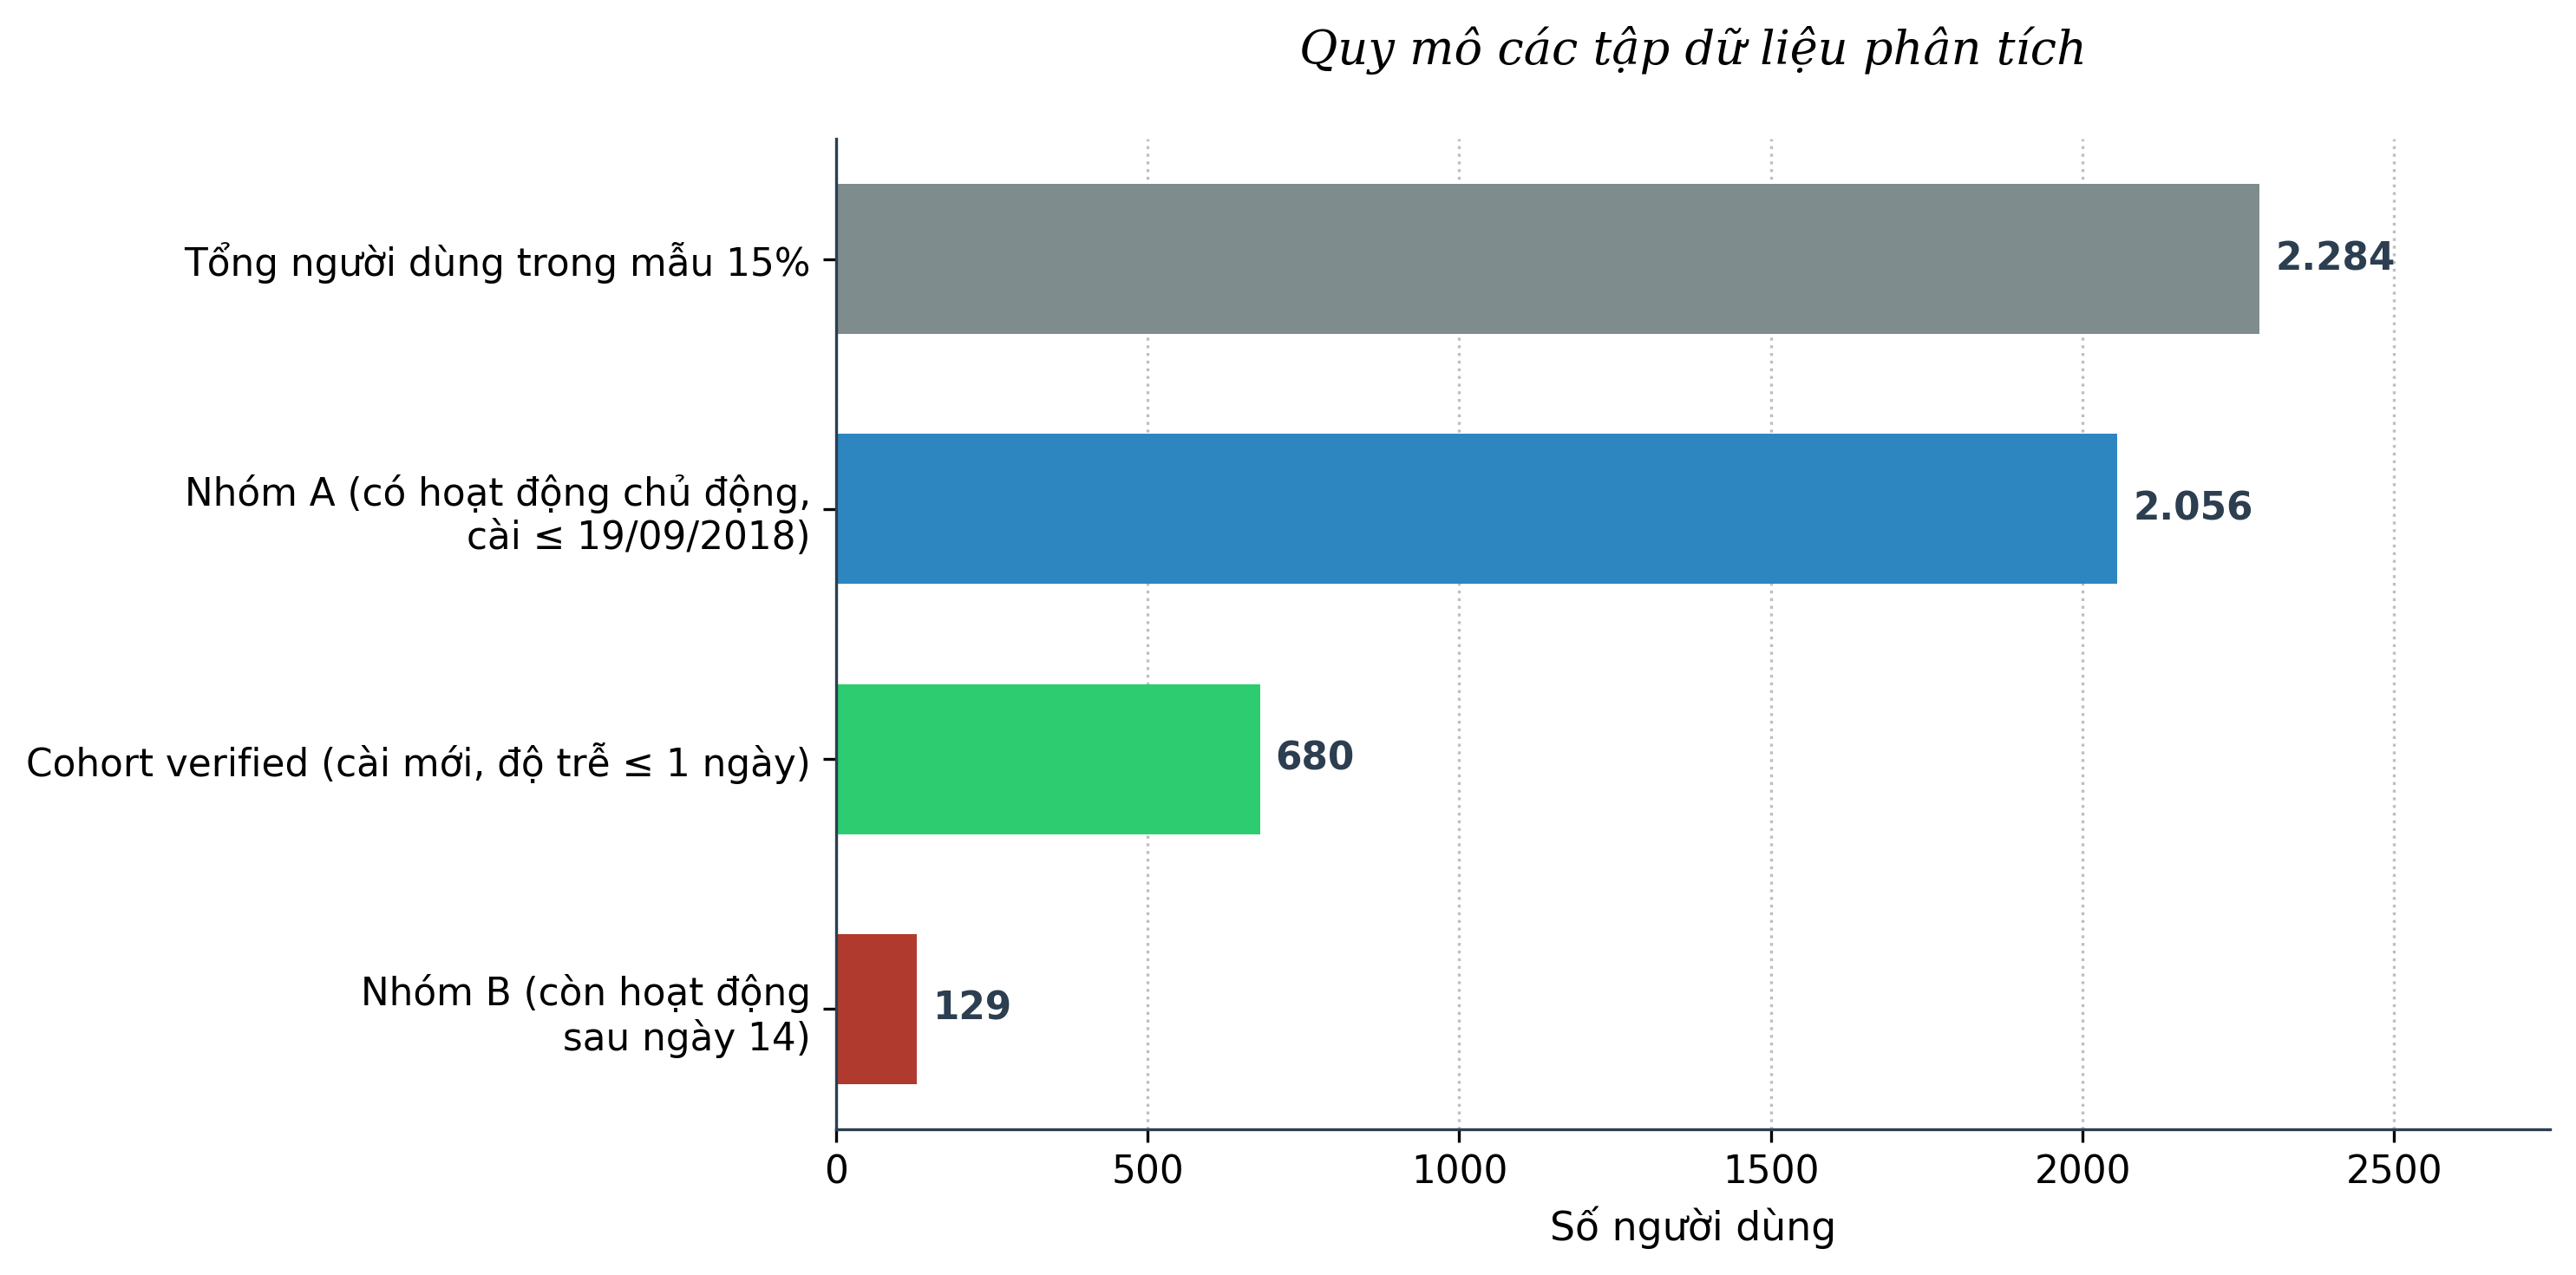

In [6]:
c = users[in_cohort(users)]
nA = len(users)
c_excl_churn = int(((c.seen < LANDMARK) & (c.event == 1)).sum())
c_excl_cens  = int(((c.event == 0) & (c['T'] <= LANDMARK)).sum())

flow = [
    ('Tổng user trong mẫu 15%', len(dim)),
    ('  Loại: chỉ có sự kiện hệ thống (không hoạt động chủ động)', len(dim) - len(base[base.user_pseudo_id.isin(evd[~evd.event_name.isin(SYSTEM_EVENTS)].user_pseudo_id)])),
    ('  Loại: cài sau horizon (END - K) chưa đủ thời gian xác định', len(base[base.user_pseudo_id.isin(evd[~evd.event_name.isin(SYSTEM_EVENTS)].user_pseudo_id)]) - nA),
    ('Nhóm A: user có hoạt động chủ động (cài <= horizon)', nA),
    ('  trong đó cài cũ (first touch trước 12/06/2018)', int((~users.is_new).sum())),
    ('  trong đó cài mới theo first touch', int(users.is_new.sum())),
    (f'Cohort đang dùng: {COHORT}', len(c)),
    ('  Loại: churn trước landmark (hoạt động cuối < ngày LANDMARK)', c_excl_churn),
    ('  Loại: censored trước/tại landmark (T <= LANDMARK)', c_excl_cens),
    ('Nhóm B (Landmark)', len(B)),
    ('  Event = 1 (churn)', int(B.event.sum())),
    ('  Event = 0 (censored)', int((B.event == 0).sum())),
]
flow_df = pd.DataFrame(flow, columns=['Bước', 'Số user'])
assert flow_df.iloc[9, 1] == flow_df.iloc[6, 1] - flow_df.iloc[7, 1] - flow_df.iloc[8, 1], 'phễu không cộng đúng'
display(flow_df)
indices_to_plot = [0, 3, 6, 9]
plot_df = flow_df.iloc[indices_to_plot].copy()

# --- BƯỚC 2: Rút gọn và chuẩn hóa nhãn (để xuống dòng cho đẹp giống ảnh) ---
label_mapping = {
    plot_df.iloc[0]['Bước']: 'Tổng người dùng trong mẫu 15%',
    plot_df.iloc[1]['Bước']: 'Nhóm A (có hoạt động chủ động,\ncài ≤ 19/09/2018)',
    plot_df.iloc[2]['Bước']: 'Cohort verified (cài mới, độ trễ ≤ 1 ngày)', 
    plot_df.iloc[3]['Bước']: 'Nhóm B (còn hoạt động\nsau ngày 14)'
}

# Áp dụng nhãn mới
plot_df['Nhãn hiển thị'] = plot_df['Bước'].map(label_mapping).fillna(plot_df['Bước'])

# Đảo ngược thứ tự để mốc đầu tiên (Tổng user) nằm ở trên cùng
plot_df = plot_df.iloc[::-1].reset_index(drop=True)

# --- BƯỚC 3: Cấu hình và Vẽ biểu đồ ---
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)

# Định nghĩa màu sắc tương ứng cho từng nhóm (theo thứ tự đảo ngược: B, Cohort, A, Tổng)
colors = ['#B03A2E', '#2ECC71', '#2E86C1', '#7F8C8D'] 

# Vẽ các thanh bar ngang
bars = ax.barh(plot_df['Nhãn hiển thị'], plot_df['Số user'], color=colors, height=0.6, edgecolor='none')

# Thêm số lượng user ở cuối mỗi thanh (định dạng dấu chấm phân tách hàng nghìn)
for bar in bars:
    width = bar.get_width()
    # Định dạng hiển thị số, ví dụ 2.284 thay vì 2284
    formatted_value = f"{int(width):,}".replace(",", ".")
    ax.text(width + 25, bar.get_y() + bar.get_height()/2, formatted_value,
            va='center', ha='left', fontsize=10.5, fontweight='bold', color='#2C3E50')

# --- BƯỚC 4: Định dạng giao diện giống ảnh gốc ---
# Thiết lập tiêu đề và nhãn trục
ax.set_title("Quy mô các tập dữ liệu phân tích\n", fontsize=13, fontfamily='serif', style='italic', loc='center')
ax.set_xlabel("Số người dùng", fontsize=11, fontweight='regular')

# Đặt giới hạn trục X rộng hơn một chút để không bị che số liệu ở cuối bar
ax.set_xlim(0, 2750) 
ax.set_xticks(range(0, 2600, 500))

# Tùy chỉnh đường lưới (gridline) dọc mờ mờ
ax.grid(axis='x', linestyle=':', alpha=0.5, color='gray')
ax.set_axisbelow(True) # Đẩy lưới ra phía sau các thanh bar

# Ẩn viền trên và viền phải
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#2C3E50')
ax.spines['bottom'].set_color('#2C3E50')

# Font chữ cho nhãn trên trục Y (được căn lề gọn gàng)
plt.yticks(fontsize=10.5)
plt.xticks(fontsize=10.5)

plt.tight_layout()
plt.show()

## 6. Phân tích độ nhạy

In [7]:
# 6a. K x cohort x L
rows = []
for k in [7, 14, 21, 30]:
    uk = build_users(k=k)
    for coh in ['verified', 'first_open', 'first_touch']:
        cc = uk[in_cohort(uk, coh)]
        for L in [7, 10, 14]:
            bb = cc[(cc.seen >= L) & (cc['T'] > L)]
            rows.append(dict(K=k, cohort=coh, L=L, n_cohort=len(cc), churn_rate=round(cc.event.mean(), 4),
                             n_B=len(bb), events_B=int(bb.event.sum())))
sens_k = pd.DataFrame(rows)
display(sens_k.pivot(index=['K', 'L'], columns='cohort', values=['n_B', 'events_B', 'churn_rate']))

# 6b. Định nghĩa 'sự kiện chủ động'
alts = {'Danh sách đã chốt': SYSTEM_EVENTS,
        '+ first_open là hệ thống': SYSTEM_EVENTS | {'first_open'},
        '+ app_exception/error là hệ thống': SYSTEM_EVENTS | {'app_exception', 'error'},
        'firebase_campaign là chủ động': SYSTEM_EVENTS - {'firebase_campaign'},
        'Mọi sự kiện đều là chủ động': set()}
rows = []
for name, s in alts.items():
    ua = build_users(system_events=s)
    cc = ua[in_cohort(ua)]; bb = cc[(cc.seen >= LANDMARK) & (cc['T'] > LANDMARK)]
    rows.append(dict(dinh_nghia=name, n_nhomA=len(ua), churn_rate_nhomA=round(ua.event.mean(), 4),
                     n_cohort=len(cc), n_B=len(bb), events_B=int(bb.event.sum())))
sens_ev = pd.DataFrame(rows); display(sens_ev)

# 6c. Cách tính T: (loại người cài muộn hay không) x (cách censor), trên cohort đang dùng
try:
    from lifelines import KaplanMeierFitter
    rows = []
    for excl in [False, True]:
        for mode in ['last_active', 'end', 'standard']:
            if mode == 'standard' and not excl: continue          # 'standard' bắt buộc loại cài muộn
            um = build_users(censor_at=mode, exclude_late=excl); cc = um[in_cohort(um)]
            km = KaplanMeierFitter().fit(cc['T'], cc.event)
            rows.append(dict(loai_cai_muon=excl, censor_at=mode, n=len(cc), events=int(cc.event.sum()),
                             trung_vi_KM=km.median_survival_time_, S_7=round(float(km.predict(7)), 3),
                             S_14=round(float(km.predict(14)), 3), S_30=round(float(km.predict(30)), 3)))
    sens_t = pd.DataFrame(rows); display(sens_t)
    s14 = sens_t.set_index(['loai_cai_muon', 'censor_at']).S_14
    print(f"S(14): giữ cài muộn -> loại cài muộn (cùng censor_at='last_active'): {s14[(False, 'last_active')]:.3f} -> {s14[(True, 'last_active')]:.3f}; "
          f"cùng censor_at='end': {s14[(False, 'end')]:.3f} -> {s14[(True, 'end')]:.3f}")
    print(f"Khi đã loại cài muộn, cách censor làm S(14) lệch tối đa {s14[True].max() - s14[True].min():.3f} "
          f"(standard = {s14[(True, 'standard')]:.3f}; so sánh để thấy phần lớn lệch đến từ việc loại người cài muộn)")
except ImportError:
    sens_t = None; print('Chưa cài lifelines')

# 6d. Cơ sở chọn K: khoảng cách giữa hai ngày hoạt động liên tiếp của cùng một user.
# Lưu ý: chỉ gồm các lần quay lại ĐÃ quan sát (khoảng im lặng kéo dài tới hết dữ liệu không có mặt) nên đuôi bị đánh giá thấp.
act_days = (evd[~evd.event_name.isin(SYSTEM_EVENTS)][['user_pseudo_id', 'event_date']]
            .drop_duplicates().sort_values(['user_pseudo_id', 'event_date']))
gaps = act_days.groupby('user_pseudo_id').event_date.diff().dt.days.dropna()
sens_gap = pd.DataFrame({'chi_so': ['số khoảng cách quan sát', 'số user có >= 2 ngày hoạt động', 'trung vị', 'p75', 'p90', 'p95', 'p99'] +
                                   [f'% khoảng cách >= {t} ngày' for t in (7, 14, 21, 30)],
                         'gia_tri': [len(gaps), int(act_days.groupby('user_pseudo_id').size().ge(2).sum())] +
                                    [float(gaps.quantile(q)) for q in (.5, .75, .9, .95, .99)] +
                                    [round(float((gaps >= t).mean() * 100), 2) for t in (7, 14, 21, 30)]})
display(sens_gap)


n_B                        events_B                      churn_rate                     
cohort first_open first_touch verified first_open first_touch verified first_open first_touch verified
K  L                                                                                                  
7  7        145.0       289.0    180.0      110.0       226.0    138.0     0.9383      0.9136   0.9363
   10       127.0       253.0    155.0       94.0       193.0    115.0     0.9383      0.9136   0.9363
   14       108.0       228.0    133.0       79.0       173.0     98.0     0.9383      0.9136   0.9363
14 7        139.0       279.0    172.0       97.0       183.0    121.0     0.9144      0.8662   0.9132
   10       120.0       242.0    146.0       81.0       152.0     99.0     0.9144      0.8662   0.9132
   14       105.0       221.0    129.0       68.0       135.0     84.0     0.9144      0.8662   0.9132
21 7        129.0       264.0    161.0       77.0       141.0     99.0     0.8745      0.8124   0.8803
   10       114.0       229.0    138.0       64.0       113.0     80.0     0.8745      0.8124   0.8803
   14        93.0       200.0    115.0       54.0       100.0     68.0     0.8745      0.8124   0.8803
30 7        113.0       232.0    142.0       66.0       110.0     87.0     0.8610      0.7740   0.8671
   10        99.0       204.0    123.0       55.0        88.0     71.0     0.8610      0.7740   0.8671
   14        88.0       184.0    110.0       45.0        75.0     59.0     0.8610      0.7740   0.8671

,dinh_nghia,n_nhomA,churn_rate_nhomA,n_cohort,n_B,events_B
0,Danh sách đã chốt,2056,0.7923,680,129,84
1,+ first_open là hệ thống,2056,0.7923,680,129,84
2,+ app_exception/error là hệ thống,2056,0.7923,680,129,84
3,firebase_campaign là chủ động,2079,0.7941,680,129,84
4,Mọi sự kiện đều là chủ động,2167,0.7965,684,145,98


,loai_cai_muon,censor_at,n,events,trung_vi_KM,S_7,S_14,S_30
0,False,last_active,787,621,2.0,0.318,0.253,0.153
1,False,end,787,621,2.0,0.354,0.290,0.182
2,True,last_active,680,621,1.0,0.265,0.210,0.128
3,True,end,680,621,1.0,0.265,0.210,0.132
4,True,standard,680,621,1.0,0.263,0.206,0.120


S(14): giữ cài muộn -> loại cài muộn (cùng censor_at='last_active'): 0.253 -> 0.210; cùng censor_at='end': 0.290 -> 0.210
Khi đã loại cài muộn, cách censor làm S(14) lệch tối đa 0.004 (standard = 0.206; so sánh để thấy phần lớn lệch đến từ việc loại người cài muộn)


,chi_so,gia_tri
0,số khoảng cách quan sát,6495.00
1,số user có >= 2 ngày hoạt động,1019.00
2,trung vị,2.00
3,p75,5.00
4,p90,15.00
5,p95,31.00
6,p99,78.00
7,% khoảng cách >= 7 ngày,20.38
8,% khoảng cách >= 14 ngày,11.13
9,% khoảng cách >= 21 ngày,7.42


## 7. Kiểm tra nhanh KM (cohort mới vs cài cũ có delayed entry)

In [8]:
try:
    from lifelines import KaplanMeierFitter
    rows = []
    cc = users[in_cohort(users)]
    km = KaplanMeierFitter().fit(cc['T'], cc.event); rows.append(('Cohort ' + COHORT, 'không cần entry', km.median_survival_time_, float(km.predict(14))))
    old = users[~users.is_new]
    km = KaplanMeierFitter().fit(old['T'], old.event, entry=old.entry); rows.append(('Cài cũ', 'có entry', km.median_survival_time_, float(km.predict(14))))
    km = KaplanMeierFitter().fit(old['T'], old.event); rows.append(('Cài cũ', 'KHÔNG entry (sai, chỉ để so sánh)', km.median_survival_time_, float(km.predict(14))))
    display(pd.DataFrame(rows, columns=['Nhóm', 'Cách tính', 'Trung vị (ngày)', 'S(14)']).round(3))
except ImportError:
    print('Chưa cài lifelines')

,Nhóm,Cách tính,Trung vị (ngày),S(14)
0,Cohort verified,không cần entry,1.0,0.206
1,Cài cũ,có entry,22.0,0.702
2,Cài cũ,"KHÔNG entry (sai, chỉ để so sánh)",415.0,0.992


## 8. Xuất dữ liệu

In [11]:
fmt = lambda df: df.assign(**{c: df[c].dt.strftime('%Y-%m-%d') for c in df.select_dtypes('datetime64[ns]').columns})
A_cols = ['user_pseudo_id', 'install_date', 'first_active', 'last_active', 'is_new', 'has_first_open', 'gap_days',
          'verified_new', 'seen', 'event', 'T', 'entry', 'platform', 'device_category', 'country']
A_out = fmt(users[A_cols])
assert {'ltv_revenue', 'has_spent'}.isdisjoint(A_out.columns), 'doanh thu cả đời không được xuất'
A_out.to_csv(os.path.join(OUT_DIR, 'group_a_survival.csv'), index=False)

# META_COLS là set -> chuyển sang list có thứ tự cố định để nối được
META_COLS_LIST = ['user_pseudo_id', 'install_date', 'first_active', 'last_active', 'seen', 'event', 'T', 'T_B', 'entry', 'is_new', 'verified_new', 'gap_days']
assert set(META_COLS_LIST) == META_COLS, 'META_COLS_LIST lệch META_COLS'
B_cols_out = META_COLS_LIST + FEATURES + ['engagement_segment']
B_out = B[B_cols_out].copy()
assert LEAKY_COLS.isdisjoint(B_out.columns), 'File nhóm B chứa cột rò rỉ/không phải đặc trưng'
assert set(B_out.columns) == META_COLS | set(FEATURES) | {'engagement_segment'}
fmt(B_out).to_csv(os.path.join(OUT_DIR, 'group_b_landmark_survival.csv'), index=False)
pd.DataFrame({'feature': FEATURES}).to_csv(os.path.join(OUT_DIR, 'feature_columns.csv'), index=False)
# kiểm tra lại từ file đã ghi
_a = pd.read_csv(os.path.join(OUT_DIR, 'group_a_survival.csv')); _b = pd.read_csv(os.path.join(OUT_DIR, 'group_b_landmark_survival.csv'))
assert {'ltv_revenue', 'has_spent'}.isdisjoint(_a.columns) and LEAKY_COLS.isdisjoint(_b.columns)
assert set(pd.read_csv(os.path.join(OUT_DIR, 'feature_columns.csv')).feature) == set(FEATURES)
print('Đã xuất: group_a_survival.csv, group_b_landmark_survival.csv,feature_columns.csv')
print('Group A:', users.shape, '| Group B:', B_out.shape)


# Lấy 2.284 user từ bảng base ban đầu
dim_pbi = base.copy()

# Lấy thông tin sinh tồn từ Nhóm A (2056 user)
a_info = users[['user_pseudo_id', 'install_date', 'first_active', 'last_active', 'is_new', 'verified_new', 'event', 'T', 'entry']].copy()
dim_pbi = dim_pbi.merge(a_info, on='user_pseudo_id', how='left')

# Với 228 user bị loại (không có trong Nhóm A), install_date tạm dùng first_touch_date
dim_pbi['install_date'] = dim_pbi['install_date'].fillna(dim_pbi['first_touch_date'])

# Tạo cột Cohort hoàn chỉnh để làm Slicer bộ lọc trong Power BI
def assign_cohort(row):
    if pd.isna(row['is_new']): return 'Bị loại (Hệ thống/Cài muộn)'
    if not row['is_new']: return 'Cài cũ'
    if row['verified_new']: return 'Cài mới verified'
    return 'Cài mới chưa xác minh'

dim_pbi['cohort'] = dim_pbi.apply(assign_cohort, axis=1)

# Nối với phân khúc của Nhóm B (129 user)
b_info = B[['user_pseudo_id', 'engagement_segment']].copy()
dim_pbi = dim_pbi.merge(b_info, on='user_pseudo_id', how='left')

# Lấp đầy giá trị cho những người không lọt qua bài test Landmark 14 ngày
dim_pbi['engagement_segment'] = dim_pbi['engagement_segment'].fillna('Không thuộc Nhóm B')

# Format ngày tháng và xuất file CSV
dim_pbi = fmt(dim_pbi)
dim_pbi.to_csv(os.path.join(OUT_DIR, 'dim_user_pbi.csv'), index=False)

POP = 'A'
 
pop_users = users if POP == 'A' else users[users.verified_new == True]
pop_ids   = set(pop_users.user_pseudo_id)
churn     = pop_users.set_index('user_pseudo_id')['event']
 
# Chế độ thường, có level_number, level 1-30, đúng quần thể
nm = lvl[lvl.user_pseudo_id.isin(pop_ids)
         & ~lvl.event_name.str.endswith('_quickplay')
         & lvl.level_number.between(1, 30)]
 
starts = nm[nm.event_name == 'level_start']
# Level bắt đầu SAU CÙNG theo thời gian (không phải level cao nhất)
last_started = starts.sort_values('event_timestamp').groupby('user_pseudo_id').level_number.last()
 
rows = []
for k in range(1, 31):
    d = nm[nm.level_number == k]
    ever_k = set(starts[starts.level_number == k].user_pseudo_id)
    last_k = set(last_started[last_started == k].index)
    stopped = [u for u in (ever_k & last_k) if churn.get(u, 0) == 1]
    rows.append({
        'level': k,
        'start_events':    int((d.event_name == 'level_start').sum()),
        'complete_events': int((d.event_name == 'level_complete').sum()),
        'fail_events':     int((d.event_name == 'level_fail').sum()),
        'users_started':   len(ever_k),
        'users_completed': int(d[d.event_name == 'level_complete'].user_pseudo_id.nunique()),
        'users_stopped_and_churned': len(stopped),
    })
 
df_level = pd.DataFrame(rows)
df_level.to_csv(os.path.join(OUT_DIR, 'level_difficulty.csv'), index=False)
print(f'Quần thể = {POP} ({len(pop_ids)} người) | level_difficulty:', df_level.shape)


Đã xuất: group_a_survival.csv, group_b_landmark_survival.csv,feature_columns.csv
Group A: (2056, 19) | Group B: (129, 35)
Quần thể = A (2056 người) | level_difficulty: (30, 7)
